<a href="https://colab.research.google.com/github/khanhbui08/lung-segmentation-unet/blob/main/Main.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import kagglehub
yoctoman_shcxr_lung_mask_path = kagglehub.dataset_download('yoctoman/shcxr-lung-mask')
kmader_pulmonary_chest_xray_abnormalities_path = kagglehub.dataset_download('kmader/pulmonary-chest-xray-abnormalities')
iamtapendu_chest_x_ray_lungs_segmentation_path = kagglehub.dataset_download('iamtapendu/chest-x-ray-lungs-segmentation')

print('Data source import complete.')


100%|██████████| 19.8M/19.8M [00:02<00:00, 10.3MB/s]

Extracting files...


Using Colab cache for faster access to the 'pulmonary-chest-xray-abnormalities' dataset.


100%|██████████| 3.59G/3.59G [02:53<00:00, 22.2MB/s]

Extracting files...


Data source import complete.


In [ ]:
# TensorFlow and Keras Imports
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, metrics
from tensorflow.keras.utils import Sequence
from tensorflow.keras.callbacks import ModelCheckpoint

# Image Processing Libraries
import cv2
from cv2 import imread,resize
from scipy.ndimage import label, find_objects

# Data Handling Libraries
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

# Visualization Libraries
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

# File and Operating System Libraries
import os

# Warnings Management
import warnings
warnings.filterwarnings('ignore')

# GPU Configuration
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
print(tf.config.list_physical_devices('GPU'))

# PATHS
# IMG_PATH = '/kaggle/input/chest-x-ray-lungs-segmentation/Chest-X-Ray/Chest-X-Ray/image/'
# MSK_PATH = '/kaggle/input/chest-x-ray-lungs-segmentation/Chest-X-Ray/Chest-X-Ray/mask/'

# Use the paths from kagglehub.dataset_download
IMG_PATH = os.path.join(iamtapendu_chest_x_ray_lungs_segmentation_path, 'Chest-X-Ray', 'Chest-X-Ray', 'image')
MSK_PATH = os.path.join(iamtapendu_chest_x_ray_lungs_segmentation_path, 'Chest-X-Ray', 'Chest-X-Ray', 'mask')

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


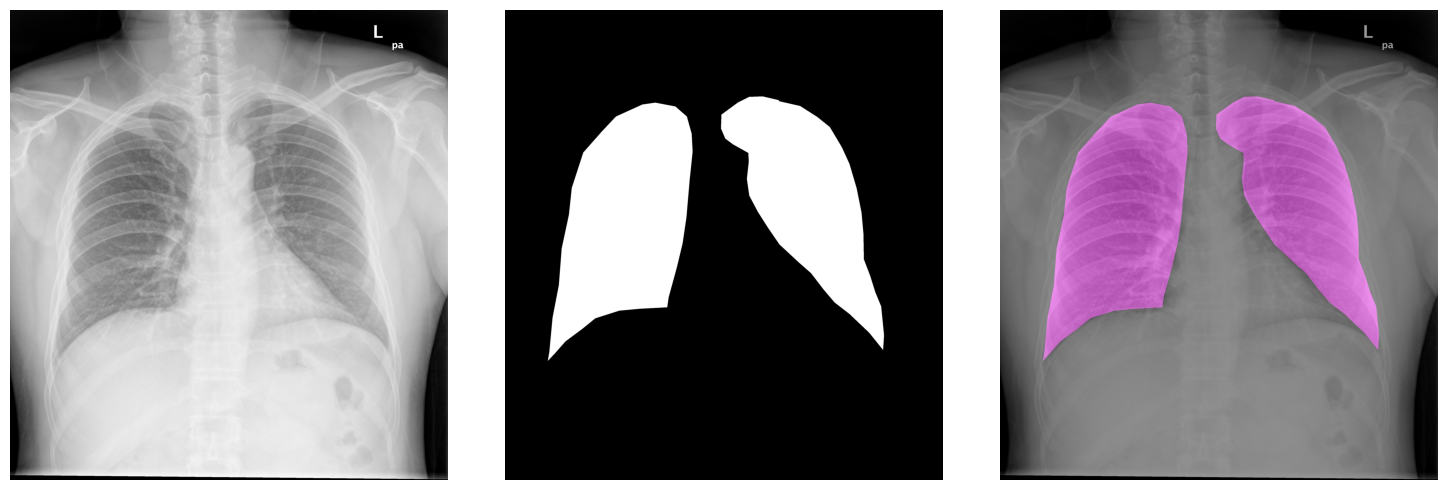

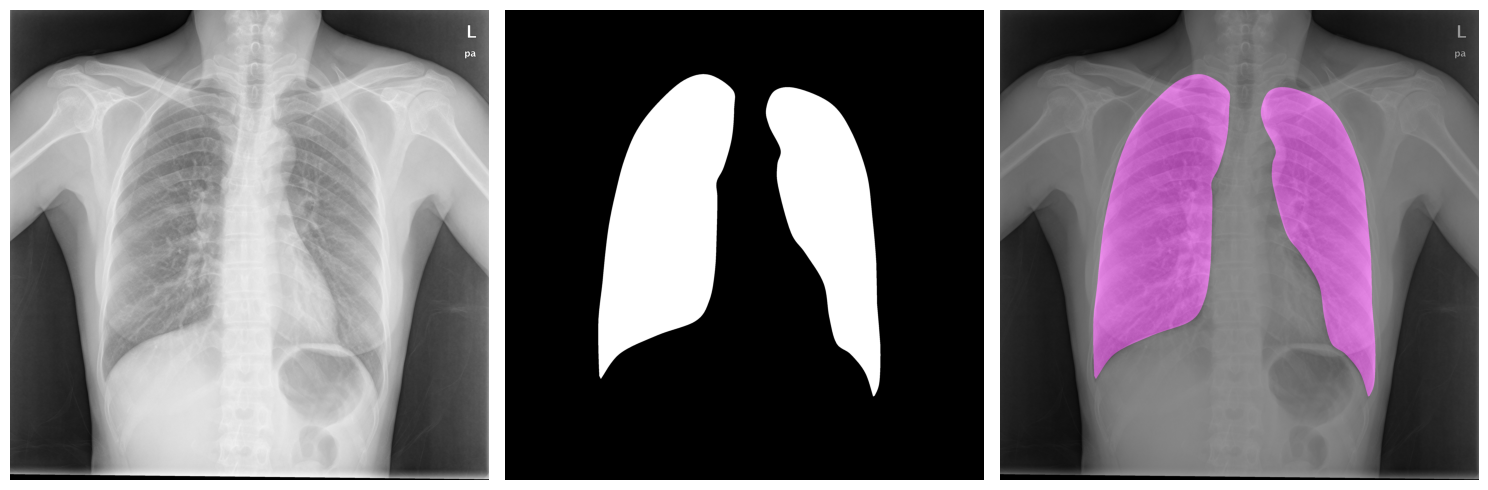

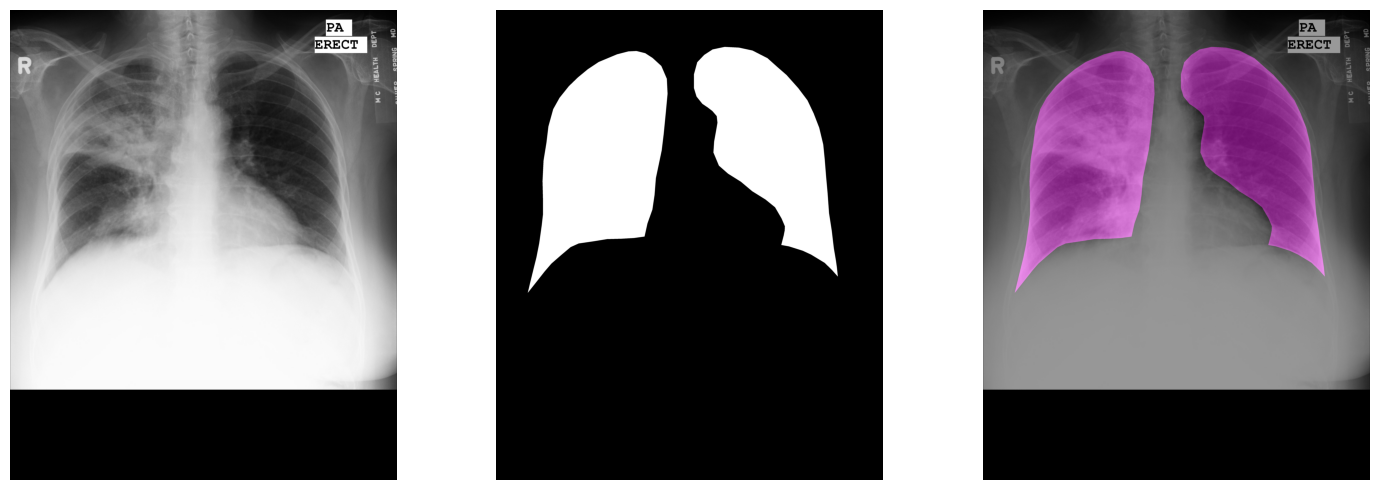

In [ ]:
def get_colored_mask(image, mask_image,color = [255,20,255]):
    mask_image_gray = cv2.cvtColor(mask_image, cv2.COLOR_BGR2GRAY)
    mask = cv2.bitwise_and(mask_image, mask_image, mask=mask_image_gray)
    mask_coord = np.where(mask!=[0,0,0])
    mask[mask_coord[0],mask_coord[1],:]= color
    ret = cv2.addWeighted(image, 0.6, mask, 0.4, 0)
    return ret

# Check if the image directory exists and is not empty
if not os.path.exists(IMG_PATH) or not os.listdir(IMG_PATH):
    print(f"Error: The directory {IMG_PATH} does not exist or is empty.")
else:
    filenames = next(os.walk(IMG_PATH))[2][:3]
    for file in filenames:
        img = imread(os.path.join(IMG_PATH, file))
        msk = imread(os.path.join(MSK_PATH, file))

        plt.figure(figsize=(15,5))

        plt.subplot(131)
        plt.imshow(img)
        plt.yticks([])
        plt.xticks([])
        plt.box(False)

        plt.subplot(132)
        plt.imshow(msk,cmap='binary_r')
        plt.yticks([])
        plt.xticks([])
        plt.box(False)

        plt.subplot(133)
        plt.imshow(get_colored_mask(img,msk))
        plt.yticks([])
        plt.xticks([])
        plt.box(False)

        plt.tight_layout()
        plt.show()

Contents of /root/.cache/kagglehub/datasets/iamtapendu/chest-x-ray-lungs-segmentation/versions/1/Chest-X-Ray/Chest-X-Ray/image: ['1391.png', '1560.png', '1646.png', '1417.png', '1018.png', '1550.png', '1660.png', '1065.png', '1488.png', '1067.png']
Contents of /root/.cache/kagglehub/datasets/iamtapendu/chest-x-ray-lungs-segmentation/versions/1/Chest-X-Ray/Chest-X-Ray/mask: ['1391.png', '1560.png', '1646.png', '1417.png', '1018.png', '1550.png', '1660.png', '1065.png', '1488.png', '1067.png']


100%|██████████| 704/704 [00:28<00:00, 25.05it/s]


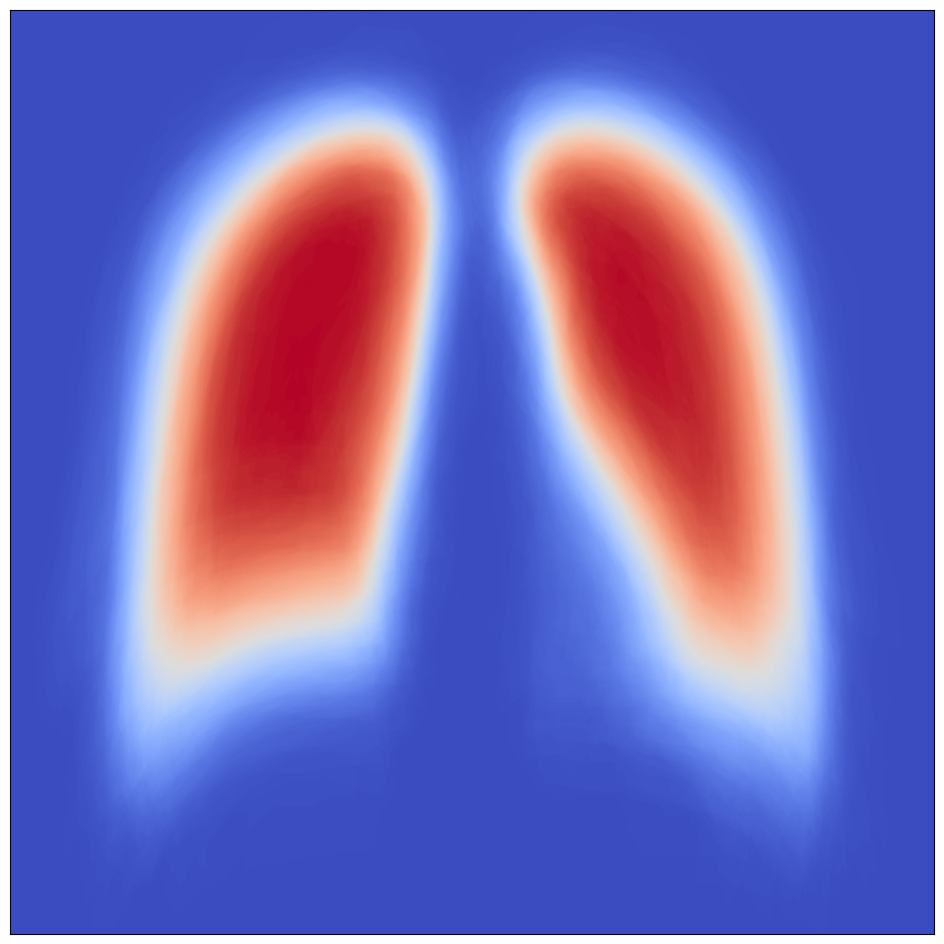

In [ ]:
# Check the contents of the image and mask directories
print(f"Contents of {IMG_PATH}: {os.listdir(IMG_PATH)[:10]}") # Print first 10 files
print(f"Contents of {MSK_PATH}: {os.listdir(MSK_PATH)[:10]}") # Print first 10 files

filenames = next(os.walk(IMG_PATH))[2]
heatmap = np.zeros((1024,1024))
for file in tqdm(filenames,total=len(filenames)):
    msk = imread(os.path.join(MSK_PATH, file),0)
    msk = resize(msk,(1024,1024))
    heatmap += msk
heatmap /= len(filenames)

plt.figure(figsize=(12,12))

plt.imshow(heatmap,cmap='coolwarm')
plt.yticks([])
plt.xticks([])

plt.show()

In [ ]:
class DataGenerator(keras.utils.PyDataset):
    def __init__(self, img_files, mask_files, batch_size=32, size=(512, 512), seed=1, shuffle=True, **kwargs):
        """
        Custom data generator for segmentation tasks.

        Args:
        - img_dir: Directory containing the input images
        - mask_dir: Directory containing the corresponding masks
        - batch_size: Number of samples per batch
        - size: The target size for resizing the images and masks
        - seed: Random seed for reproducibility
        - shuffle: Whether to shuffle the dataset after each epoch
        """
        super().__init__(**kwargs)

        # List image and mask files
        self.img_filenames = img_files
        self.mask_filenames = mask_files

        self.batch_size = batch_size
        self.size = size
        self.seed = seed
        self.shuffle = shuffle

        # Ensure the number of images matches the number of masks
        assert len(self.img_filenames) == len(self.mask_filenames), \
            "The number of images and masks must be the same"

        self.indexes = np.arange(len(self.img_filenames))  # Indices for shuffling

        # If shuffle is enabled, shuffle the indices after each epoch
        if self.shuffle:
            self.on_epoch_end()

    def __len__(self):
        """
        Returns the number of batches per epoch.
        """
        return int(np.floor(len(self.img_filenames) / self.batch_size))

    def __getitem__(self, index):
        """
        Generates a batch of data (images and corresponding masks).

        Args:
        - index: The index of the batch.

        Returns:
        - A batch of images and masks
        """
        # Get batch indices
        batch_indices = self.indexes[index * self.batch_size : (index + 1) * self.batch_size]

        # Initialize empty arrays for the batch
        images = []
        masks = []

        for i, idx in enumerate(batch_indices):
            # Load and preprocess image
            img = imread(os.path.join(IMG_PATH, self.img_filenames[idx]),0)  # Read image
            img = resize(img, self.size)  # Resize to target size
            img = img / 255.0  # Normalize to [0, 1]

            # Load and preprocess mask
            mask = imread(os.path.join(MSK_PATH, self.mask_filenames[idx]),0)  # Read mask
            mask = resize(mask, self.size)  # Resize to target size
            # mask = cv2.dilate(mask, np.ones((15, 15), np.uint8), iterations=1)
            mask = np.expand_dims(mask, axis=-1)  # Add channel dimension
            mask = mask / 255.0  # Normalize to [0, 1]
            mask[mask > 0.5] = 1  # Binary mask

            # Add image and mask to the batch arrays
            images.append(img)
            masks.append(mask)

        return np.array(images), np.array(masks)

    def on_epoch_end(self):
        """
        Shuffle the dataset after each epoch.
        """
        if self.shuffle:
            np.random.shuffle(self.indexes)

img_files, msk_files = sorted(os.listdir(IMG_PATH)), sorted(os.listdir(MSK_PATH))

train_img_files, val_img_files, train_msk_files, val_msk_files = train_test_split(img_files,msk_files,test_size=0.3,random_state=1)

train_data = DataGenerator(
    img_files=train_img_files,
    mask_files=train_msk_files,
    batch_size=8,
    size=(512, 512),
    workers=4,
    use_multiprocessing=True
)

val_data = DataGenerator(
    img_files=val_img_files,
    mask_files=val_msk_files,
    batch_size=8,
    size=(512, 512),
    workers=4,
    use_multiprocessing=True
)

In [ ]:
def attention_gate(x, g, inter_channels):
    theta_x = layers.Conv2D(inter_channels, 1, padding='same')(x)
    phi_g = layers.Conv2D(inter_channels, 1, padding='same')(g)
    add_xg = layers.Add()([theta_x, phi_g])
    act = layers.Activation('relu')(add_xg)
    psi = layers.Conv2D(1, 1, padding='same')(act)
    psi = layers.Activation('sigmoid')(psi)
    att = layers.Multiply()([x, psi])
    return att

# U-Net
def unet(input_shape, num_classes):
    inputs = layers.Input(shape=input_shape)

    # Encoder
    conv1 = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(inputs)
    conv1 = layers.BatchNormalization()(conv1)
    conv1 = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(conv1)
    conv1 = layers.BatchNormalization()(conv1)
    pool1 = layers.MaxPooling2D(pool_size=(2, 2), strides=(2, 2))(conv1)

    conv2 = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(pool1)
    conv2 = layers.BatchNormalization()(conv2)
    conv2 = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(conv2)
    conv2 = layers.BatchNormalization()(conv2)
    pool2 = layers.MaxPooling2D(pool_size=(2, 2), strides=(2, 2))(conv2)

    conv3 = layers.Conv2D(256, (3, 3), activation='relu', padding='same')(pool2)
    conv3 = layers.BatchNormalization()(conv3)
    conv3 = layers.Conv2D(256, (3, 3), activation='relu', padding='same')(conv3)
    conv3 = layers.BatchNormalization()(conv3)
    pool3 = layers.MaxPooling2D(pool_size=(2, 2), strides=(2, 2))(conv3)

    conv4 = layers.Conv2D(512, (3, 3), activation='relu', padding='same')(pool3)
    conv4 = layers.BatchNormalization()(conv4)
    conv4 = layers.Conv2D(512, (3, 3), activation='relu', padding='same')(conv4)
    conv4 = layers.BatchNormalization()(conv4)

    # Decoder with Attention
    up6 = layers.Conv2DTranspose(256, (2, 2), strides=(2, 2), padding='same')(conv4)
    att6 = attention_gate(conv3, up6, 128)
    merge6 = layers.concatenate([up6, att6])
    conv6 = layers.Conv2D(256, (3, 3), activation='relu', padding='same')(merge6)
    conv6 = layers.BatchNormalization()(conv6)
    conv6 = layers.Conv2D(256, (3, 3), activation='relu', padding='same')(conv6)
    conv6 = layers.BatchNormalization()(conv6)

    up7 = layers.Conv2DTranspose(128, (2, 2), strides=(2, 2), padding='same')(conv6)
    att7 = attention_gate(conv2, up7, 64)
    merge7 = layers.concatenate([up7, att7])
    conv7 = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(merge7)
    conv7 = layers.BatchNormalization()(conv7)
    conv7 = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(conv7)
    conv7 = layers.BatchNormalization()(conv7)

    up8 = layers.Conv2DTranspose(64, (2, 2), strides=(2, 2), padding='same')(conv7)
    att8 = attention_gate(conv1, up8, 32)
    merge8 = layers.concatenate([up8, att8])
    conv8 = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(merge8)
    conv8 = layers.BatchNormalization()(conv8)
    conv8 = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(conv8)
    conv8 = layers.BatchNormalization()(conv8)

    outputs = layers.Conv2D(num_classes, (1, 1), activation='sigmoid')(conv8)

    model = models.Model(inputs=[inputs], outputs=[outputs])
    return model


In [ ]:
# Jaccard Index Metric
def jaccard_index(y_true, y_pred, smooth=100):
    """Calculates the Jaccard index (IoU), useful for evaluating the model's performance."""
    y_true_f = tf.reshape(tf.cast(y_true, tf.float32), [-1])  # Flatten and cast ground truth
    y_pred_f = tf.reshape(tf.cast(y_pred, tf.float32), [-1])  # Flatten and cast predictions
    intersection = tf.reduce_sum(y_true_f * y_pred_f)  # Compute intersection
    total = tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) - intersection  # Total pixels
    return (intersection + smooth) / (total + smooth)


def dice_coefficient(y_true, y_pred, smooth=1):
    # Flatten and cast true and predicted masks to float32
    y_true_f = tf.reshape(tf.cast(y_true, tf.float32), [-1])  # Flatten and cast y_true to float32
    y_pred_f = tf.reshape(tf.cast(y_pred, tf.float32), [-1])  # Flatten and cast y_pred to float32

    # Calculate the intersection between the true and predicted masks
    intersection = tf.reduce_sum(y_true_f * y_pred_f)

    # Calculate the Dice coefficient using the formula
    return (2. * intersection + smooth) / (tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + smooth)

# Instantiate the model
model = unet(input_shape=(512, 512, 1), num_classes=1)

# Using the metrics in model compilation
model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy',dice_coefficient,jaccard_index])

In [ ]:
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau


# 2. ModelCheckpoint: Save the best model

checkpoint = ModelCheckpoint(
    'best_model.keras',
    monitor='val_dice_coefficient',
    verbose=1,
    save_best_only=True,
    mode='max',
    save_weights_only=False
)


#ReduceLROnPlateau: Decrease learning rate
reduce_lr = ReduceLROnPlateau(
    monitor='val_dice_coefficient',
    mode='max',
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)


# 4. Train model
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=70,
    callbacks=[checkpoint, reduce_lr]
)


Epoch 1/70
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7960 - dice_coefficient: 0.5720 - jaccard_index: 0.4097 - loss: 0.4755
Epoch 1: val_dice_coefficient improved from -inf to 0.39643, saving model to best_model.keras
61/61 ━━━━━━━━━━━━━━━━━━━━ 296s 3s/step - accuracy: 0.7972 - dice_coefficient: 0.5735 - jaccard_index: 0.4112 - loss: 0.4732 - val_accuracy: 0.2476 - val_dice_coefficient: 0.3964 - val_jaccard_index: 0.2478 - val_loss: 565.9159 - learning_rate: 0.0010
Epoch 2/70
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9313 - dice_coefficient: 0.7862 - jaccard_index: 0.6492 - loss: 0.1852
Epoch 2: val_dice_coefficient improved from 0.39643 to 0.41762, saving model to best_model.keras
61/61 ━━━━━━━━━━━━━━━━━━━━ 144s 2s/step - accuracy: 0.9314 - dice_coefficient: 0.7865 - jaccard_index: 0.6496 - loss: 0.1850 - val_accuracy: 0.3160 - val_dice_coefficient: 0.4176 - val_jaccard_index: 0.2643 - val_loss: 70.2692 - learning_rate: 0.0010
Epoch 3/70
61/61 ━━━━━━━━━━━━━━━━━━━━ 

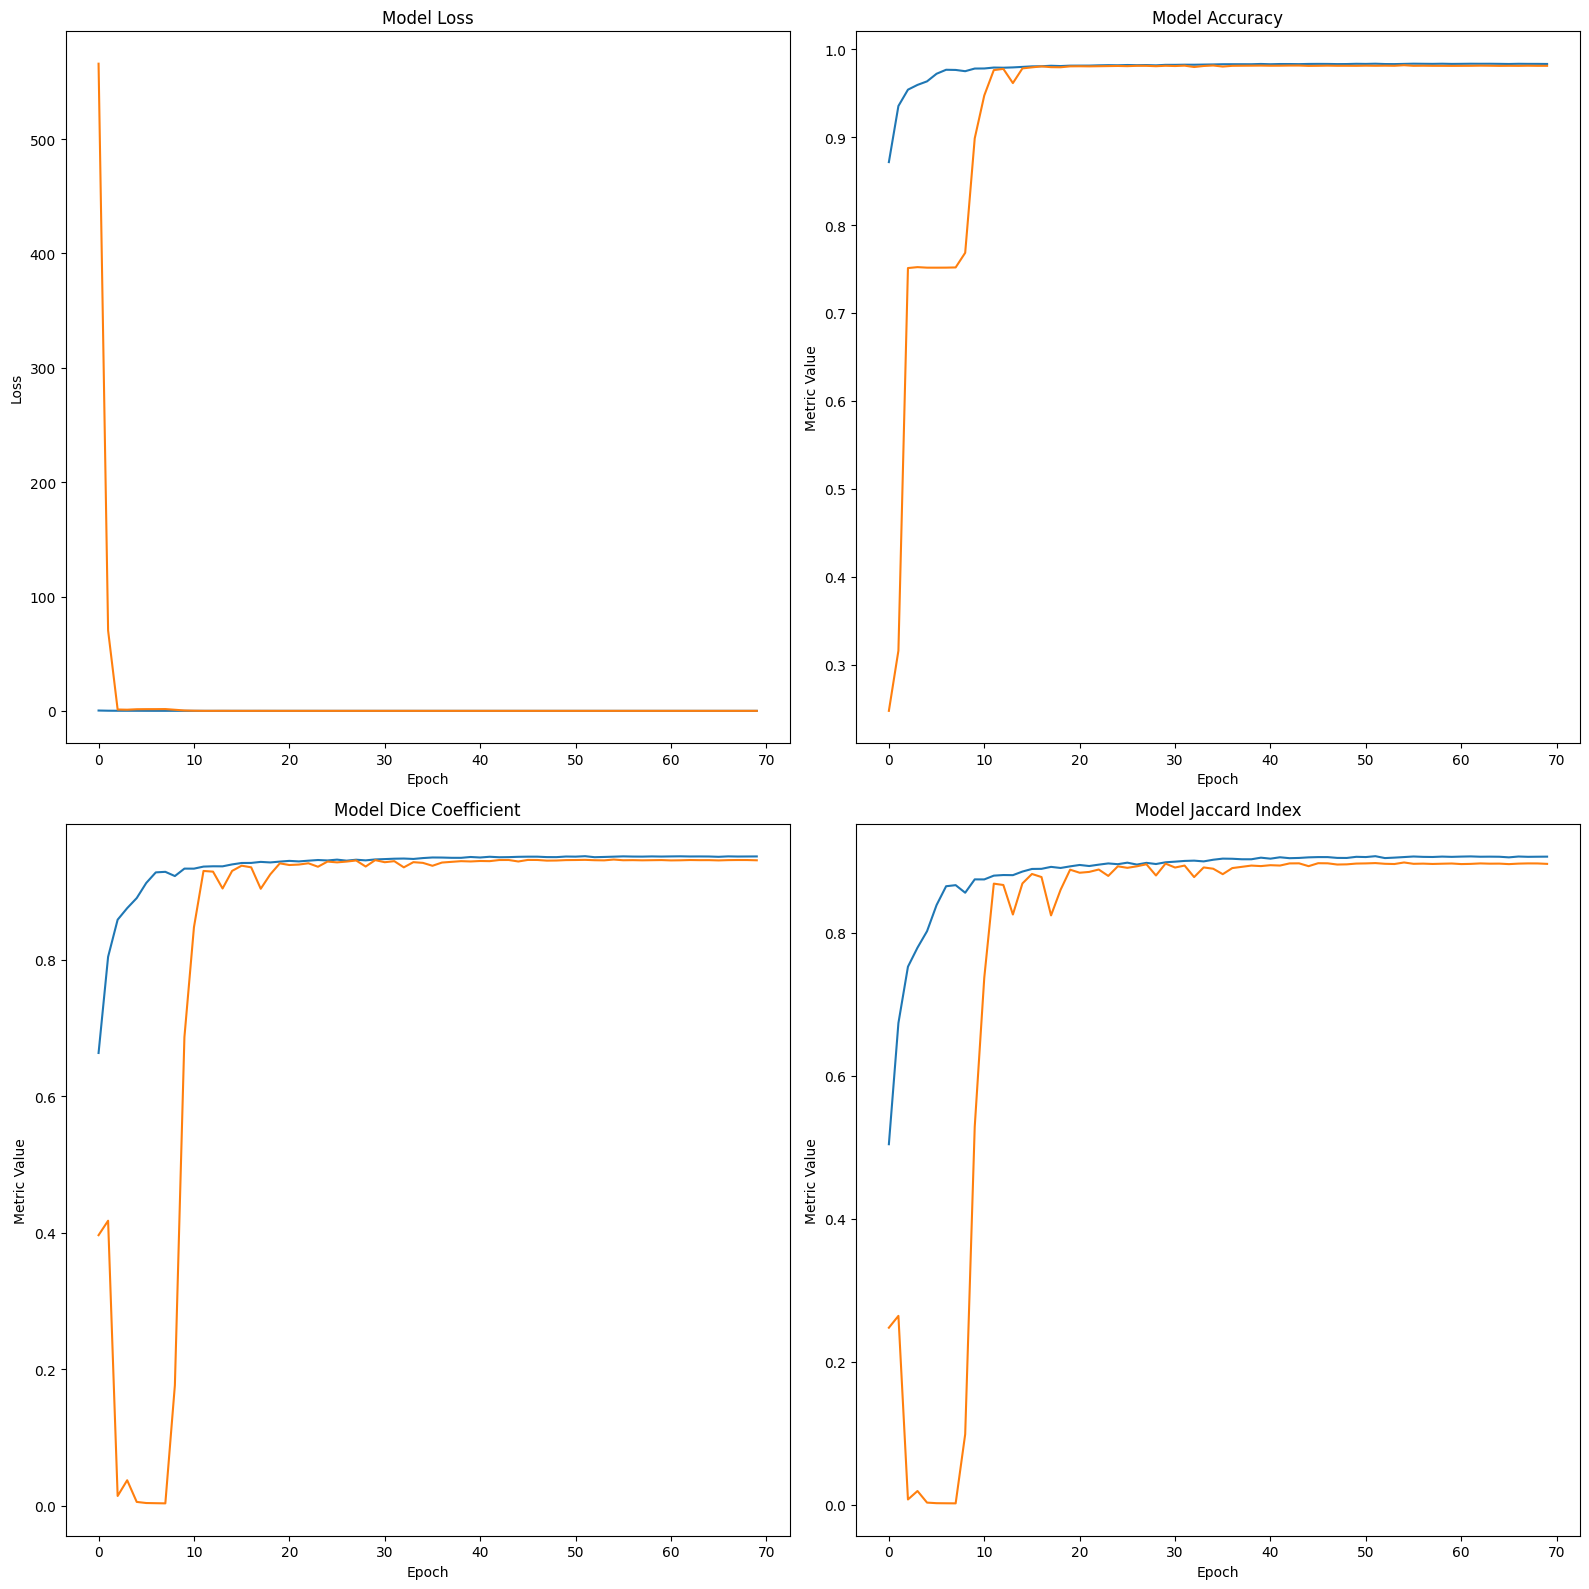

In [ ]:
# Plot training & validation loss values
plt.figure(figsize=(16,16))
plt.subplot(221)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')

plt.subplot(222)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.ylabel('Metric Value')
plt.xlabel('Epoch')

plt.subplot(223)
plt.plot(history.history['dice_coefficient'], label='Train Dice Coefficient')
plt.plot(history.history['val_dice_coefficient'], label='Validation Dice Coefficient')
plt.title('Model Dice Coefficient')
plt.ylabel('Metric Value')
plt.xlabel('Epoch')

plt.subplot(224)
plt.plot(history.history['jaccard_index'], label='Train Jaccard Index')
plt.plot(history.history['val_jaccard_index'], label='Validation Jaccard Index')
plt.title('Model Jaccard Index')
plt.ylabel('Metric Value')
plt.xlabel('Epoch')

plt.tight_layout()
plt.show()

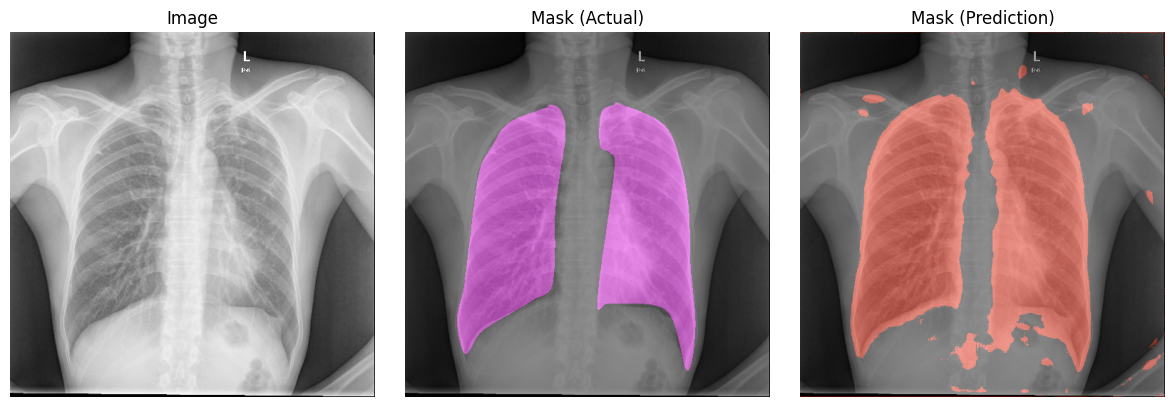

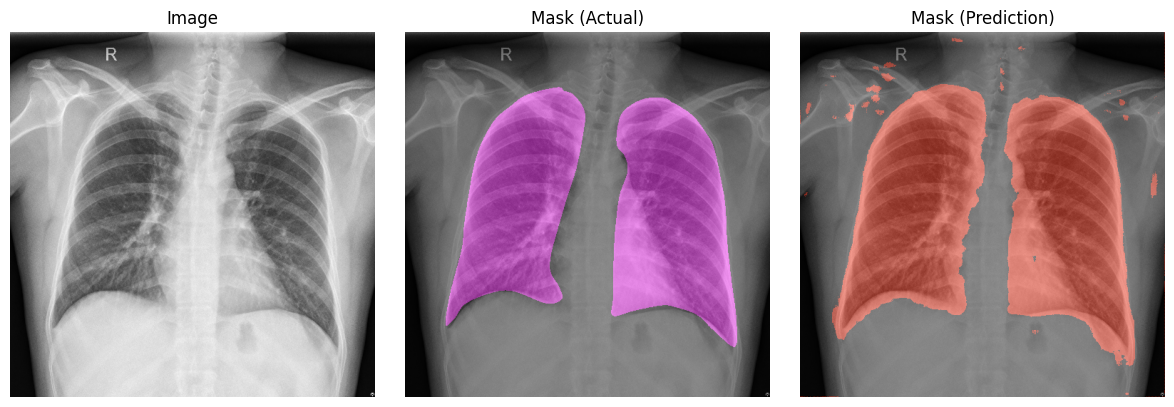

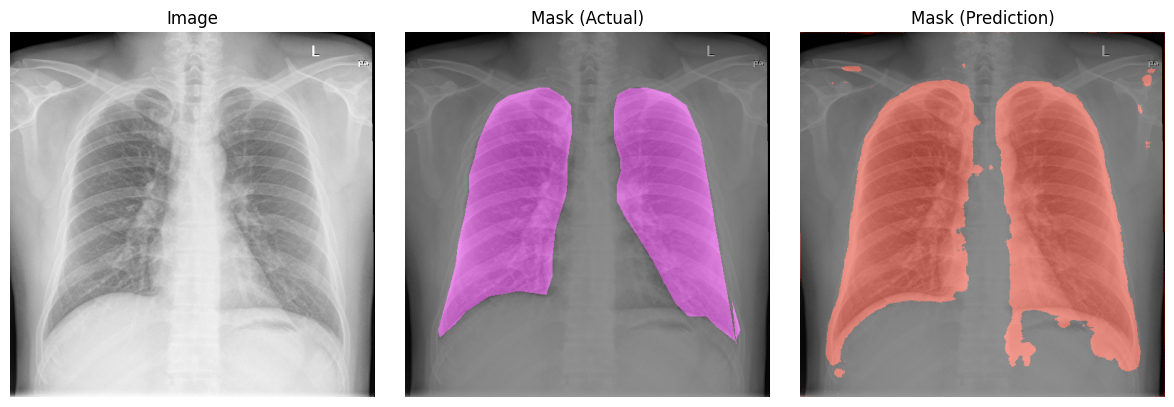

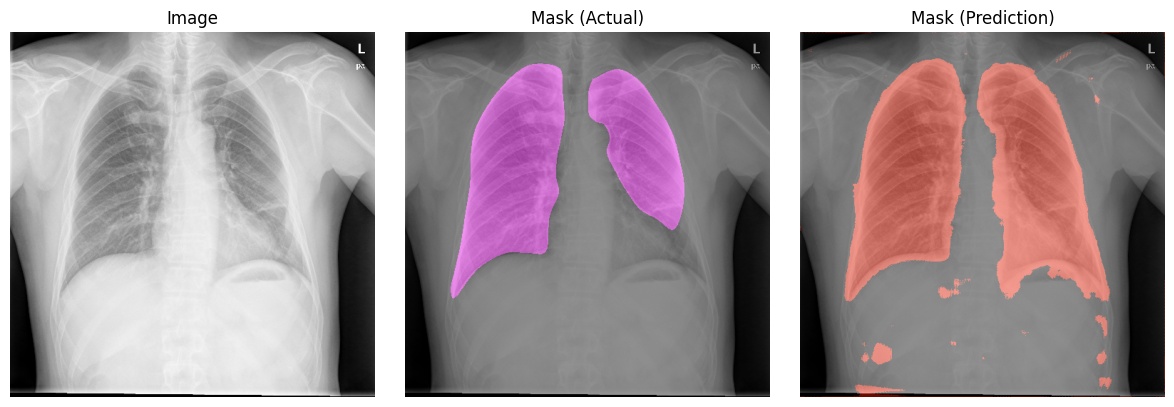

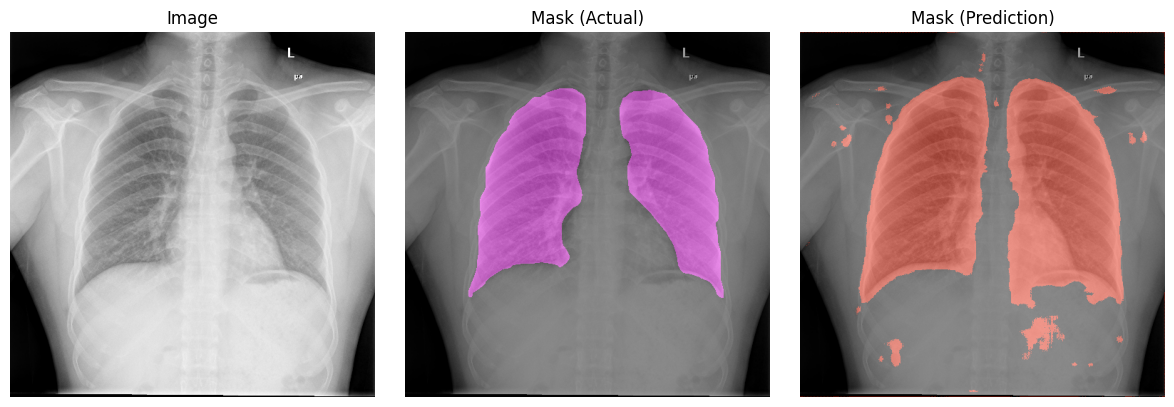

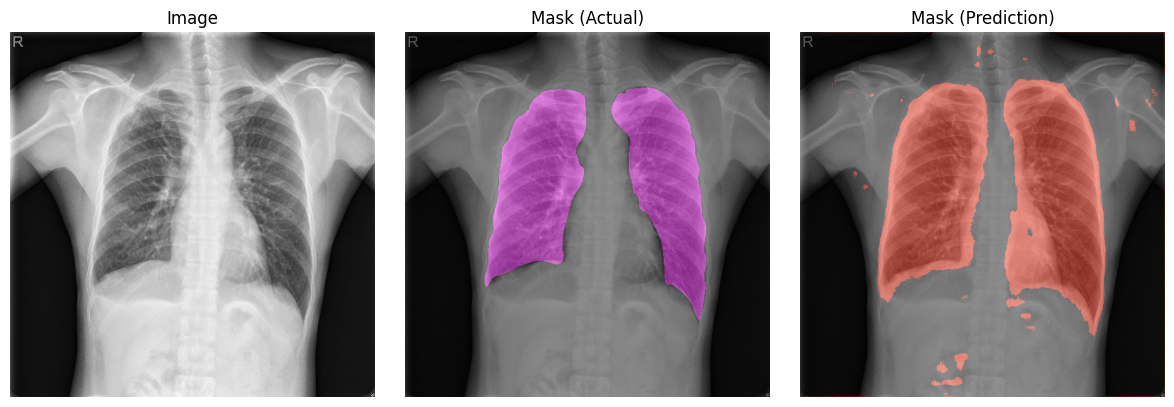

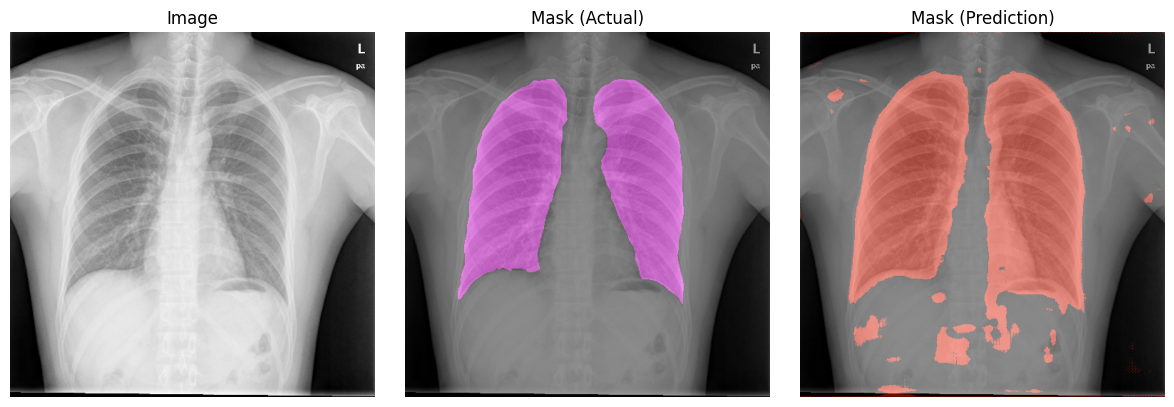

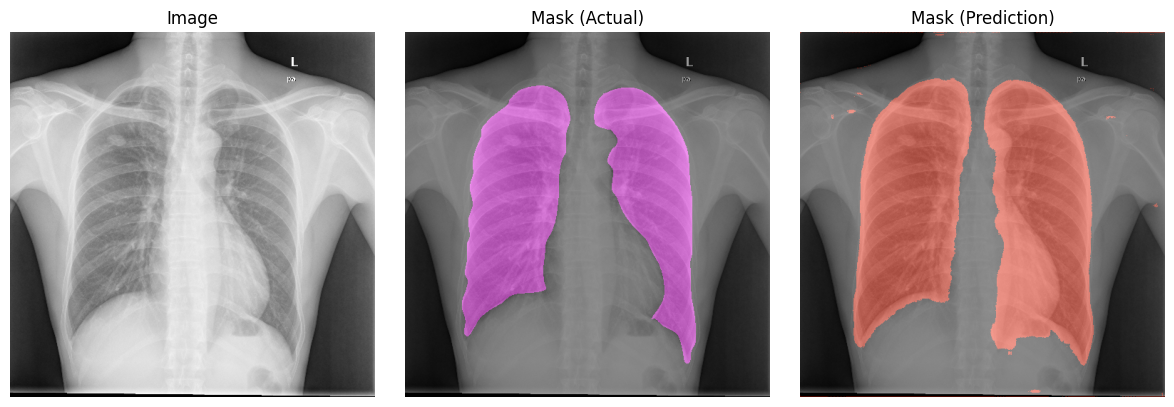

In [ ]:
imgs, msks  = val_data.__getitem__(1)

for img,msk in zip(imgs,msks):
    img = np.expand_dims(img, axis=0)
    pred = (np.squeeze(model.predict(img,verbose=0))*255).astype(np.uint8)
    img = (np.squeeze(img) * 255).astype(np.uint8)
    msk = (msk*255).astype(np.uint8)

    # Convert grayscale image to RGB
    img= cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
    msk = cv2.cvtColor(msk, cv2.COLOR_GRAY2RGB)
    pred = cv2.cvtColor(pred, cv2.COLOR_GRAY2RGB)

    plt.figure(figsize=(12,4))

    plt.subplot(131)
    plt.imshow(img)
    plt.title('Image')
    plt.yticks([])
    plt.xticks([])
    plt.box(False)

    plt.subplot(132)
    plt.imshow(get_colored_mask(img,msk))
    plt.title('Mask (Actual)')
    plt.yticks([])
    plt.xticks([])
    plt.box(False)

    plt.subplot(133)
    plt.imshow(get_colored_mask(img,pred,color = [255,30,0]))
    plt.title('Mask (Prediction)')
    plt.yticks([])
    plt.xticks([])
    plt.box(False)

    plt.tight_layout()
    plt.show()